# Previsão de preços de imóveis — House Prices

**Autor:** Cleber de Jesus Salustiano  
**Matricula:** 20251mpca0170

---

**Desafio Kaggle:** [House Prices: Advanced Regression Techniques](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques)  
**Problema:** regressão supervisionada. A partir de atributos de casas em Ames, Iowa, estimar o preço final de venda (`SalePrice`).

Este estudo compara um modelo de referência, Ridge e três ensembles de árvores: Random Forest, Extra Trees e Gradient Boosting. O fluxo inclui exploração, pré-processamento em pipelines, busca aleatória de hiperparâmetros com validação cruzada e avaliação em dados mantidos fora do ajuste. As escolhas priorizam técnicas do curso: divisão treino/teste, generalização, árvores e ensembles, métricas e ajuste automatizado.


## Como reproduzir

1. Baixe os arquivos `train.csv` e, opcionalmente, `test.csv` na página da competição Kaggle. É necessário ter conta Kaggle e aceitar as regras da competição.
2. Coloque os CSVs em `tarefa_house_prices/data/`. Eles não são versionados neste repositório.
3. Instale as dependências listadas em `requirements.txt`.
4. Abra este notebook no Jupyter e execute as células em ordem. O notebook procura a pasta `data/` do projeto mesmo se o Jupyter for iniciado na raiz do repositório ou em `notebooks/`.

A avaliação local usa uma divisão estratificada? Não: `SalePrice` é contínuo, então usamos uma divisão aleatória reprodutível, sem estratificação. O `test.csv` oficial do Kaggle não contém rótulos; portanto, não é usado para calcular métricas.


In [1]:
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import ExtraTreesRegressor, GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    make_scorer, mean_absolute_error, mean_squared_error,
    mean_squared_log_error, r2_score,
)
from sklearn.model_selection import (
    RandomizedSearchCV, KFold, cross_val_score, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

print(f"Python: {sys.version.split()[0]} | pandas: {pd.__version__} | scikit-learn: {sklearn.__version__}")

Python: 3.11.14 | pandas: 3.0.3 | scikit-learn: 1.8.0


## 1. Carregamento e conferência

Carrego `train.csv`, verifico as colunas obrigatórias e confirmo as dimensões da base. Para a prévia ficar legível, mostro cinco campos completos e representativos; a tabela original continua com todas as 81 colunas para as etapas seguintes.


In [2]:
data_candidates = [
    Path.cwd() / "tarefa_house_prices" / "data",
    Path.cwd().parent / "data",
    Path.cwd() / "data",
]
DATA_DIR = next((p for p in data_candidates if (p / "train.csv").is_file()), data_candidates[0])
TRAIN_PATH = DATA_DIR / "train.csv"
if not TRAIN_PATH.is_file():
    raise FileNotFoundError(
        f"Não encontrei {TRAIN_PATH}. Baixe train.csv do Kaggle e salve em tarefa_house_prices/data/."
    )

df = pd.read_csv(TRAIN_PATH)
required = {"Id", "SalePrice"}
missing_required = required - set(df.columns)
if missing_required:
    raise ValueError(f"Colunas obrigatórias ausentes: {sorted(missing_required)}")

print(f"Formato: {df.shape[0]:,} linhas × {df.shape[1]} colunas")
preview_columns = ["Id", "OverallQual", "GrLivArea", "Neighborhood", "SalePrice"]
display(df[preview_columns].head())
display(df.dtypes.value_counts().rename_axis("tipo").to_frame("quantidade de colunas"))

Formato: 1,460 linhas × 81 colunas


,Id,OverallQual,GrLivArea,Neighborhood,SalePrice
0,1,7,1710,CollgCr,208500
1,2,6,1262,Veenker,181500
2,3,7,1786,CollgCr,223500
3,4,7,1717,Crawfor,140000
4,5,8,2198,NoRidge,250000


,quantidade de colunas
tipo,
str,43
int64,35
float64,3


## 2. Exploração inicial

Para manter a leitura curta, resumo cinco variáveis numéricas ligadas ao preço e cinco atributos categóricos representativos. A coluna de ausentes explicita a cobertura de cada atributo. Os histogramas mostram a distribuição de `SalePrice` e de `log1p(SalePrice)`, transformação usada pelo modelo porque o desafio avalia RMSLE.


,count,mean,median,std,min,max,ausentes
SalePrice,1460.0,180921.20,163000.0,79442.50,34900.0,755000.0,0
OverallQual,1460.0,6.10,6.0,1.38,1.0,10.0,0
GrLivArea,1460.0,1515.46,1464.0,525.48,334.0,5642.0,0
TotalBsmtSF,1460.0,1057.43,991.5,438.71,0.0,6110.0,0
GarageCars,1460.0,1.77,2.0,0.75,0.0,4.0,0


,categorias,mais frequente,frequência,ausentes
Neighborhood,25,NAmes,225,0
HouseStyle,8,1Story,726,0
KitchenQual,4,TA,735,0
MSZoning,5,RL,1151,0
SaleCondition,6,Normal,1198,0


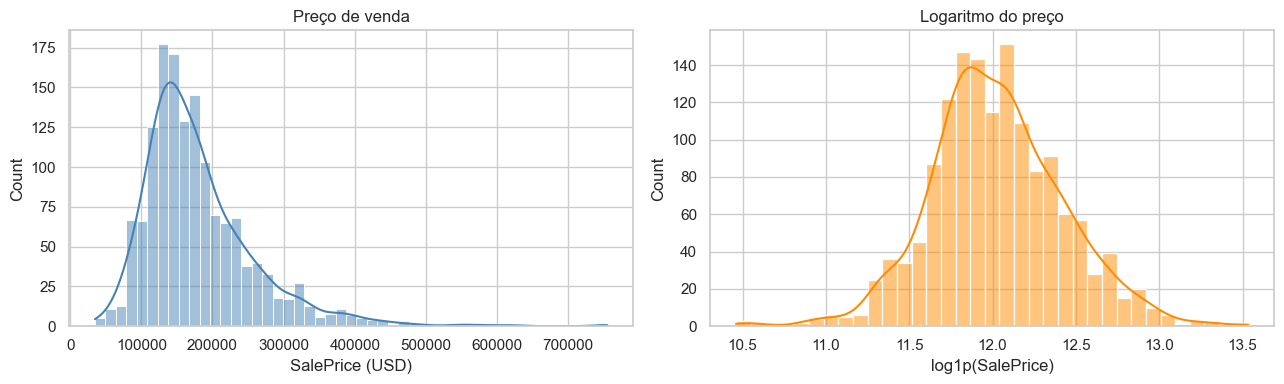

In [3]:
numeric_features_summary = ["SalePrice", "OverallQual", "GrLivArea", "TotalBsmtSF", "GarageCars"]
numeric_summary = df[numeric_features_summary].agg(["count", "mean", "median", "std", "min", "max"]).T
numeric_summary["ausentes"] = df[numeric_features_summary].isna().sum()
display(numeric_summary.round(2))

categorical_features_summary = ["Neighborhood", "HouseStyle", "KitchenQual", "MSZoning", "SaleCondition"]
categorical_summary = pd.DataFrame({
    "categorias": df[categorical_features_summary].nunique(),
    "mais frequente": df[categorical_features_summary].mode().iloc[0],
    "frequência": df[categorical_features_summary].apply(lambda column: column.value_counts().max()),
    "ausentes": df[categorical_features_summary].isna().sum(),
})
display(categorical_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["SalePrice"], kde=True, ax=axes[0], color="steelblue")
axes[0].set(title="Preço de venda", xlabel="SalePrice (USD)")
sns.histplot(np.log1p(df["SalePrice"]), kde=True, ax=axes[1], color="darkorange")
axes[1].set(title="Logaritmo do preço", xlabel="log1p(SalePrice)")
plt.tight_layout()
plt.show()

## 3. Ausências, distribuições e relações

Uma ausência pode significar que o atributo não existe na casa (por exemplo, garagem) ou que a informação não foi registrada. Para não inventar um único significado durante a exploração, primeiro quantificamos as ausências; no pipeline, valores numéricos serão imputados pela mediana e categorias ausentes receberão uma categoria explícita. A imputação é ajustada somente dentro de cada partição de treino.


,percentual ausente
PoolQC,99.520548
MiscFeature,96.301370
Alley,93.767123
Fence,80.753425
MasVnrType,59.726027
FireplaceQu,47.260274
LotFrontage,17.739726
GarageYrBlt,5.547945
GarageCond,5.547945
GarageType,5.547945


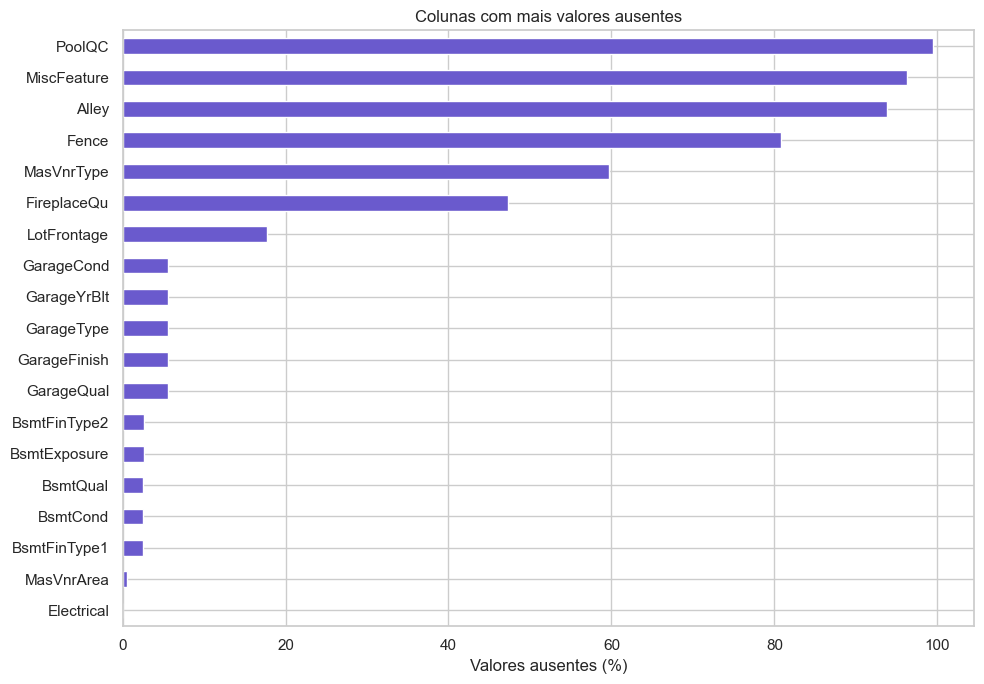

In [4]:
missing = (df.isna().mean() * 100).sort_values(ascending=False)
missing = missing[missing > 0]
display(missing.head(25).rename("percentual ausente").to_frame())

plt.figure(figsize=(10, 7))
missing.head(25).sort_values().plot(kind="barh", color="slateblue")
plt.xlabel("Valores ausentes (%)")
plt.title("Colunas com mais valores ausentes")
plt.tight_layout()
plt.show()

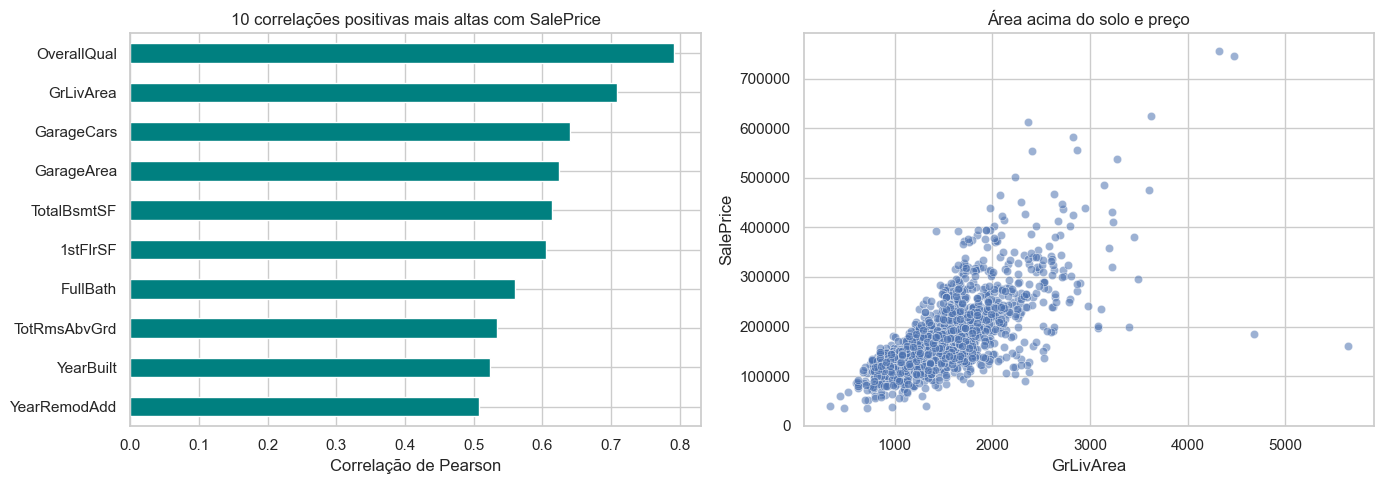

In [5]:
# Relações numéricas iniciais: correlação de Pearson é exploratória, não prova causalidade.
numeric = df.select_dtypes(include=np.number)
corr_target = numeric.corr(numeric_only=True)["SalePrice"].drop("SalePrice").sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
corr_target.tail(10).plot(kind="barh", ax=axes[0], color="teal")
axes[0].set_title("10 correlações positivas mais altas com SalePrice")
axes[0].set_xlabel("Correlação de Pearson")
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", alpha=.55, ax=axes[1])
axes[1].set_title("Área acima do solo e preço")
plt.tight_layout()
plt.show()

**Leitura da análise:** correlação e gráficos orientam perguntas e ajudam a detectar observações atípicas, mas não serão usados para selecionar variáveis olhando o conjunto de teste interno. Os modelos usam as colunas disponíveis, com exceção do identificador, e a validação cruzada estima a capacidade de generalização.


## 4. Engenharia de atributo e divisão dos dados

O `TotalArea` foi criado somando a área habitável acima do solo (`GrLivArea`) e a área do porão (`TotalBsmtSF`). A combinação representa uma medida simples do espaço construído e deixa os atributos originais disponíveis para os modelos. Ausência de área do porão é tratada como zero apenas nessa soma, pois uma casa sem porão contribui com zero para a área total.

A divisão 80/20 é feita antes de ajustar qualquer imputador, codificador ou modelo. O conjunto de teste interno só será usado na avaliação final.


In [6]:
def add_features(frame: pd.DataFrame) -> pd.DataFrame:
    """Adiciona uma medida simples de área construída sem consultar o alvo."""
    result = frame.copy()
    above = result["GrLivArea"] if "GrLivArea" in result else 0
    basement = result["TotalBsmtSF"].fillna(0) if "TotalBsmtSF" in result else 0
    result["TotalArea"] = above + basement
    return result

X = add_features(df.drop(columns=["SalePrice", "Id"]))
y = df["SalePrice"].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)
print(f"Treino: {X_train.shape}; teste interno: {X_test.shape}")

Treino: (1168, 80); teste interno: (292, 80)


## 5. Pré-processamento sem vazamento

A regressão Ridge depende da escala, então padronizamos atributos numéricos. Para a Random Forest, a escala não é necessária, mas o mesmo pré-processamento permite comparar modelos dentro de um pipeline consistente. A codificação one-hot transforma categorias em colunas binárias e ignora categorias novas que apareçam em uma partição.

O `ColumnTransformer` é ajustado novamente em cada dobra da validação cruzada, evitando que medianas, médias, desvios ou categorias do conjunto de validação influenciem o treino.


In [7]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="ausente_ou_nao_aplicavel")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=True)),
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])
print(f"Features numéricas: {len(numeric_features)} | categóricas: {len(categorical_features)}")

Features numéricas: 37 | categóricas: 43


## 6. Modelos e métrica de seleção

A métrica oficial da competição é RMSLE, que compara os logaritmos dos preços. Os modelos abaixo aprendem `log1p(SalePrice)` por meio de `TransformedTargetRegressor`; suas previsões voltam à escala original. Além de RMSLE, reportaremos MAE, RMSE e R² para facilitar a interpretação. O modelo de referência prevê sempre a mediana do treino.

Vamos comparar Ridge com três ensembles baseados em árvores: Random Forest, Extra Trees e Gradient Boosting. As famílias têm comportamentos diferentes: bagging reduz variância ao combinar árvores, enquanto boosting constrói árvores sequencialmente para corrigir erros. A comparação usa a mesma validação cruzada e a métrica RMSLE, alinhada ao desafio.


In [8]:
def rmsle(y_true, y_pred):
    """RMSLE com proteção contra previsões negativas, inválidas para preços."""
    y_pred = np.maximum(np.asarray(y_pred), 0)
    return float(np.sqrt(mean_squared_log_error(y_true, y_pred)))

rmsle_scorer = make_scorer(rmsle, greater_is_better=False)
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

def make_model(regressor):
    pipeline = Pipeline([
        ("preprocess", preprocessor),
        ("model", regressor),
    ])
    return TransformedTargetRegressor(
        regressor=pipeline, func=np.log1p, inverse_func=np.expm1
    )

baseline = DummyRegressor(strategy="median")
baseline_scores = cross_val_score(
    baseline, X_train, y_train, cv=cv, scoring=rmsle_scorer, n_jobs=-1
)
print(f"RMSLE de referência (média CV): {-baseline_scores.mean():.4f} ± {baseline_scores.std():.4f}")

RMSLE de referência (média CV): 0.3905 ± 0.0184


## 7. Busca de hiperparâmetros com validação cruzada

Para cada família, `RandomizedSearchCV` testa 15 configurações amostradas de espaços definidos abaixo, com cinco dobras. A busca usa somente `X_train` e `y_train`; o conjunto de teste interno permanece fora da seleção. Essa busca é mais ampla que uma pequena grade fixa e mantém o tempo de execução razoável. A semente torna a amostragem reprodutível.


In [9]:
search_spaces = {
    "Ridge": (
        Ridge(),
        {"regressor__model__alpha": [0.1, 0.3, 1, 3, 10, 30, 100, 300, 1000]},
    ),
    "Random Forest": (
        RandomForestRegressor(random_state=SEED, n_jobs=1),
        {
            "regressor__model__n_estimators": [200, 400, 600],
            "regressor__model__max_features": [0.25, 0.4, 0.55, 0.7, 1.0],
            "regressor__model__min_samples_leaf": [1, 2, 4, 6],
            "regressor__model__max_depth": [None, 10, 16, 24],
        },
    ),
    "Extra Trees": (
        ExtraTreesRegressor(random_state=SEED, n_jobs=1),
        {
            "regressor__model__n_estimators": [200, 400, 600],
            "regressor__model__max_features": [0.25, 0.4, 0.55, 0.7, 1.0],
            "regressor__model__min_samples_leaf": [1, 2, 4, 6],
            "regressor__model__max_depth": [None, 10, 16, 24],
        },
    ),
    "Gradient Boosting": (
        GradientBoostingRegressor(random_state=SEED),
        {
            "regressor__model__n_estimators": [100, 200, 300, 500, 700],
            "regressor__model__learning_rate": [0.01, 0.02, 0.03, 0.05, 0.08],
            "regressor__model__max_depth": [1, 2, 3],
            "regressor__model__min_samples_leaf": [2, 4, 6, 8],
            "regressor__model__subsample": [0.65, 0.8, 1.0],
            "regressor__model__max_features": [0.5, 0.75, 1.0],
        },
    ),
}

searches = {}
for family, (regressor, parameter_space) in search_spaces.items():
    family_search = RandomizedSearchCV(
        estimator=make_model(regressor),
        param_distributions=parameter_space,
        n_iter=15,
        scoring=rmsle_scorer,
        cv=cv,
        n_jobs=-1,
        random_state=SEED,
        refit=True,
        return_train_score=True,
    )
    family_search.fit(X_train, y_train)
    searches[family] = family_search
    print(
        f"{family}: RMSLE CV = {-family_search.best_score_:.4f} "
        f"(± {family_search.cv_results_['std_test_score'][family_search.best_index_]:.4f})"
    )

best_family = max(searches, key=lambda family: searches[family].best_score_)
search = searches[best_family]

# Se Gradient Boosting vencer a busca ampla, refinamos os valores ao redor do melhor candidato.
# Esta etapa também usa apenas as dobras de treino, sem acessar o teste interno.
if best_family == "Gradient Boosting":
    refined_space = {
        "regressor__model__n_estimators": [500, 700, 900, 1100, 1300],
        "regressor__model__learning_rate": [0.01, 0.02, 0.025, 0.03, 0.04, 0.05],
        "regressor__model__max_depth": [2, 3, 4],
        "regressor__model__min_samples_leaf": [3, 4, 6, 8, 10],
        "regressor__model__subsample": [0.55, 0.65, 0.75, 0.85, 1.0],
        "regressor__model__max_features": [0.35, 0.5, 0.65, 0.8, 1.0],
    }
    refinement = RandomizedSearchCV(
        estimator=make_model(GradientBoostingRegressor(random_state=SEED)),
        param_distributions=refined_space,
        n_iter=24,
        scoring=rmsle_scorer,
        cv=cv,
        n_jobs=-1,
        random_state=SEED + 1,
        refit=True,
        return_train_score=True,
    )
    refinement.fit(X_train, y_train)
    searches["Gradient Boosting refinado"] = refinement
    if refinement.best_score_ > search.best_score_:
        best_family = "Gradient Boosting refinado"
        search = refinement
    print(f"Refinamento de Gradient Boosting: RMSLE CV = {-refinement.best_score_:.4f}")

print(f"\nMelhor família: {best_family}")
print("Melhores hiperparâmetros:", search.best_params_)
print(f"Melhor RMSLE média na validação cruzada: {-search.best_score_:.4f}")

/Users/clebersalustiano/Documents/neural-network-master-works/.venv/lib/python3.11/site-packages/sklearn/model_selection/_search.py:324: UserWarning: The total space of parameters 9 is smaller than n_iter=15. Running 9 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Ridge: RMSLE CV = 0.1414 (± 0.0310)


Random Forest: RMSLE CV = 0.1394 (± 0.0160)


Extra Trees: RMSLE CV = 0.1387 (± 0.0124)


Gradient Boosting: RMSLE CV = 0.1204 (± 0.0159)


Refinamento de Gradient Boosting: RMSLE CV = 0.1195

Melhor família: Gradient Boosting refinado
Melhores hiperparâmetros: {'regressor__model__subsample': 0.55, 'regressor__model__n_estimators': 900, 'regressor__model__min_samples_leaf': 10, 'regressor__model__max_features': 0.8, 'regressor__model__max_depth': 2, 'regressor__model__learning_rate': 0.04}
Melhor RMSLE média na validação cruzada: 0.1195


In [10]:
rows = [{
    "modelo": "DummyRegressor (mediana)",
    "RMSLE média CV": -baseline_scores.mean(),
    "desvio padrão CV": baseline_scores.std(),
    "melhores parâmetros": "—",
}]
for family, family_search in searches.items():
    rows.append({
        "modelo": family,
        "RMSLE média CV": -family_search.best_score_,
        "desvio padrão CV": family_search.cv_results_["std_test_score"][family_search.best_index_],
        "melhores parâmetros": family_search.best_params_,
    })
comparison = pd.DataFrame(rows).sort_values("RMSLE média CV").reset_index(drop=True)
display(comparison)

,modelo,RMSLE média CV,desvio padrão CV,melhores parâmetros
0,Gradient Boosting refinado,0.119525,0.014816,"{'regressor__model__subsample': 0.55, 'regress..."
1,Gradient Boosting,0.120364,0.015868,"{'regressor__model__subsample': 0.65, 'regress..."
2,Extra Trees,0.138748,0.012428,"{'regressor__model__n_estimators': 600, 'regre..."
3,Random Forest,0.139437,0.015974,"{'regressor__model__n_estimators': 600, 'regre..."
4,Ridge,0.141360,0.031033,{'regressor__model__alpha': 30}
5,DummyRegressor (mediana),0.390482,0.018432,—


A comparação ajuda a verificar se a complexidade compensa: o candidato escolhido deve superar a referência e apresentar desempenho consistente entre as dobras. Uma diferença pequena entre candidatos pode indicar que o resultado depende mais dos dados disponíveis do que da escolha do estimador.


## 8. Avaliação final no teste interno

Depois da seleção por validação cruzada, avaliamos o melhor estimador uma única vez no conjunto interno reservado. As métricas estão na escala original de preço, exceto RMSLE, que acompanha o critério da competição. Não usamos o resultado do teste para voltar a escolher hiperparâmetros.


In [11]:
best_model = search.best_estimator_
y_pred = best_model.predict(X_test)
metrics = {
    "RMSLE": rmsle(y_test, y_pred),
    "MAE (USD)": mean_absolute_error(y_test, y_pred),
    "RMSE (USD)": np.sqrt(mean_squared_error(y_test, y_pred)),
    "R²": r2_score(y_test, y_pred),
}
display(pd.Series(metrics, name="resultado no teste interno").to_frame())
print(f"Modelo selecionado: {best_family} — {search.best_estimator_.regressor_.named_steps['model']}")

,resultado no teste interno
RMSLE,0.134290
MAE (USD),15859.202614
RMSE (USD),27838.641078
R²,0.898963


Modelo selecionado: Gradient Boosting refinado — GradientBoostingRegressor(learning_rate=0.04, max_depth=2, max_features=0.8,
                          min_samples_leaf=10, n_estimators=900,
                          random_state=42, subsample=0.55)


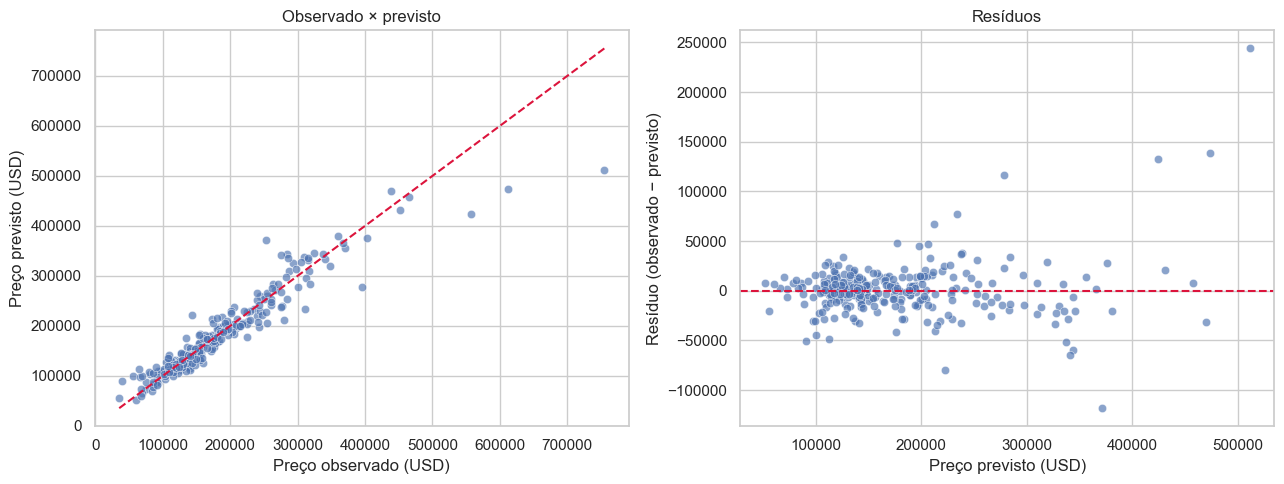

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(x=y_test, y=y_pred, alpha=.65, ax=axes[0])
limits = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(limits, limits, linestyle="--", color="crimson")
axes[0].set(xlabel="Preço observado (USD)", ylabel="Preço previsto (USD)", title="Observado × previsto")

residuals = y_test - y_pred
sns.scatterplot(x=y_pred, y=residuals, alpha=.65, ax=axes[1])
axes[1].axhline(0, linestyle="--", color="crimson")
axes[1].set(xlabel="Preço previsto (USD)", ylabel="Resíduo (observado − previsto)", title="Resíduos")
plt.tight_layout()
plt.show()

### Importância das features

Usamos importância por permutação no teste interno: embaralhar uma coluna e observar a mudança na pontuação estima o quanto o modelo depende dela. Isso é uma leitura descritiva do modelo, não uma relação causal. Features correlacionadas podem compartilhar importância.


,aumento de RMSLE ao permutar
TotalArea,0.132081
OverallQual,0.063148
YearBuilt,0.011409
OverallCond,0.010861
YearRemodAdd,0.009670
GrLivArea,0.008982
GarageCars,0.008201
LotArea,0.008114
Neighborhood,0.004180
SaleCondition,0.004022


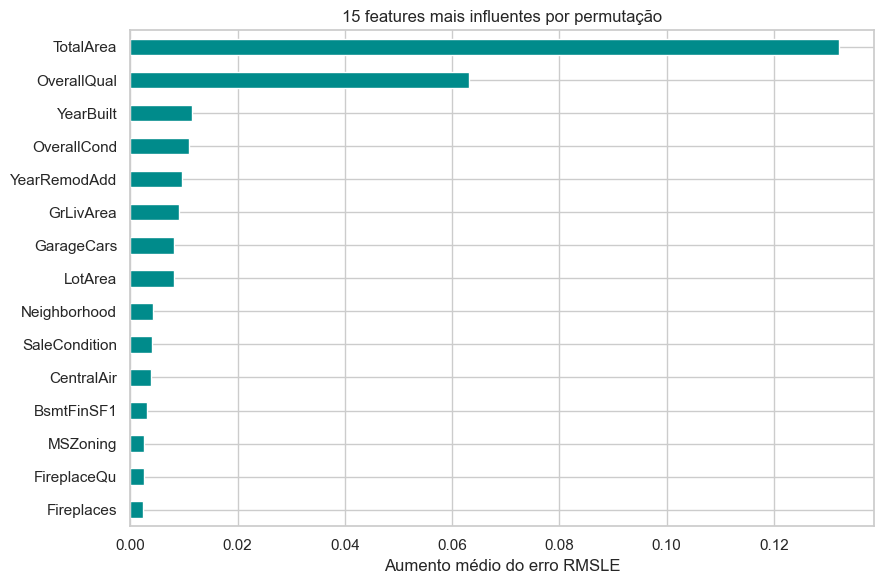

In [13]:
permutation = permutation_importance(
    best_model, X_test, y_test, scoring=rmsle_scorer,
    n_repeats=8, random_state=SEED, n_jobs=-1,
)
importance = pd.Series(permutation.importances_mean, index=X_test.columns).sort_values(ascending=False)
display(importance.head(15).rename("aumento de RMSLE ao permutar").to_frame())
importance.head(15).sort_values().plot(kind="barh", figsize=(9, 6), color="darkcyan")
plt.xlabel("Aumento médio do erro RMSLE")
plt.title("15 features mais influentes por permutação")
plt.tight_layout()
plt.show()

## 9. Conclusão e limitações

A célula seguinte resume as métricas do modelo selecionado em relação ao preditor de referência. Ela interpreta o erro absoluto médio em relação ao preço mediano do conjunto de treino; essa comparação ajuda a dar escala ao erro, mas não substitui a análise dos gráficos.


In [14]:
baseline_price = DummyRegressor(strategy="median").fit(X_train, y_train).predict(X_test)
baseline_test_rmsle = rmsle(y_test, baseline_price)
mae_share = metrics["MAE (USD)"] / y_train.median() * 100
selected_name = best_family
print(f"Modelo selecionado por validação cruzada: {selected_name}.")
print(f"No teste interno, o RMSLE foi {metrics['RMSLE']:.4f}, contra {baseline_test_rmsle:.4f} da referência baseada na mediana.")
print(f"O erro absoluto médio foi de US$ {metrics['MAE (USD)']:,.0f}, equivalente a {mae_share:.1f}% do preço mediano do treino.")
print(f"O R² no teste interno foi {metrics['R²']:.3f}; interprete-o junto dos resíduos, pois ele não mostra sozinho o tamanho dos erros em dólares.")

Modelo selecionado por validação cruzada: Gradient Boosting refinado.
No teste interno, o RMSLE foi 0.1343, contra 0.4323 da referência baseada na mediana.
O erro absoluto médio foi de US$ 15,859, equivalente a 9.6% do preço mediano do treino.
O R² no teste interno foi 0.899; interprete-o junto dos resíduos, pois ele não mostra sozinho o tamanho dos erros em dólares.


## 10. (Opcional) Gerar arquivo para submissão Kaggle

In [ ]:
KAGGLE_TEST_PATH = DATA_DIR / "test.csv"
kaggle_test = pd.read_csv(KAGGLE_TEST_PATH)
test_ids = kaggle_test["Id"].copy()
X_full = add_features(df.drop(columns=["SalePrice", "Id"]))
X_kaggle = add_features(kaggle_test.drop(columns=["Id"]))

final_model = search.best_estimator_
final_model.fit(X_full, y)
submission = pd.DataFrame({
    "Id": test_ids,
    "SalePrice": np.maximum(final_model.predict(X_kaggle), 0),
})
output_path = DATA_DIR / "submission_house_prices.csv"
submission.to_csv(output_path, index=False)
print(f"Arquivo salvo em: {output_path.resolve()}")
display(submission.head())

Arquivo salvo em: /Users/clebersalustiano/Documents/neural-network-master-works/tarefa_house_prices/data/submission_house_prices.csv


,Id,SalePrice
0,1461,123200.196964
1,1462,160333.110014
2,1463,182916.693775
3,1464,188147.832132
4,1465,193868.690201
